# EDA de la jointure des matchs de football

Cette exploration suit la démarche du notebook Toyota, adaptée à notre contexte. Elle avance dans un ordre simple :

1. **Qu'ai-je ?** Comprendre la taille, les observations, les variables et leurs types.
2. **Puis-je faire confiance aux données ?** Contrôler les valeurs manquantes, les doublons, les catégories, les valeurs impossibles et les dates.
3. **Que racontent ces variables ?** Explorer les distributions, le temps, les groupes et les relations entre variables.

Chaque partie se termine par une réponse explicite à la question posée.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.style.use("seaborn-v0_8-whitegrid")

data_dir = Path("../data")
if not data_dir.exists():
    data_dir = Path("data")

train = pd.read_csv(data_dir / "train.csv", low_memory=False)
scores = pd.read_csv(data_dir / "train_target_and_scores.csv")

df = train.merge(
    scores[["id", "score"]],
    on="id",
    how="left",
    validate="one_to_one",
)

# Table enrichie réservée à l'EDA : le DataFrame df reste la jointure brute.
eda = df.copy()
eda["match_date_parsed"] = pd.to_datetime(eda["match_date"], errors="coerce")
goals = eda["score"].astype("string").str.extract(r"^(\d+)\s*-\s*(\d+)$")
eda["home_goals"] = pd.to_numeric(goals[0], errors="coerce")
eda["away_goals"] = pd.to_numeric(goals[1], errors="coerce")
eda["total_goals"] = eda["home_goals"] + eda["away_goals"]

home_history_goals = [f"home_team_history_goal_{i}" for i in range(1, 11)]
away_history_goals = [f"away_team_history_goal_{i}" for i in range(1, 11)]
home_history_ratings = [f"home_team_history_rating_{i}" for i in range(1, 11)]
away_history_ratings = [f"away_team_history_rating_{i}" for i in range(1, 11)]
eda["home_recent_goals_mean"] = eda[home_history_goals].mean(axis=1)
eda["away_recent_goals_mean"] = eda[away_history_goals].mean(axis=1)
eda["home_recent_rating_mean"] = eda[home_history_ratings].mean(axis=1)
eda["away_recent_rating_mean"] = eda[away_history_ratings].mean(axis=1)
eda["recent_rating_difference"] = eda["home_recent_rating_mean"] - eda["away_recent_rating_mean"]

# Partie 1 — Qu'ai-je ?

On commence comme dans le notebook Toyota : observer la table avant de chercher à l'expliquer. `shape`, `head`, `sample`, `columns`, `info` et `describe` répondent chacun à une question précise.

## 1.1 Dimensions et structure

In [2]:
print(f"La jointure contient {df.shape[0]:,} lignes et {df.shape[1]} colonnes.")
df.shape

La jointure contient 110,938 lignes et 191 colonnes.


(110938, 191)

### À quoi ressemble une observation ?

In [3]:
df.head()

,id,target,home_team_name,away_team_name,match_date,league_name,league_id,is_cup,home_team_coach_id,away_team_coach_id,home_team_history_match_date_1,home_team_history_match_date_2,home_team_history_match_date_3,home_team_history_match_date_4,home_team_history_match_date_5,...,away_team_history_coach_7,away_team_history_coach_8,away_team_history_coach_9,away_team_history_coach_10,away_team_history_league_id_1,away_team_history_league_id_2,away_team_history_league_id_3,away_team_history_league_id_4,away_team_history_league_id_5,away_team_history_league_id_6,away_team_history_league_id_7,away_team_history_league_id_8,away_team_history_league_id_9,away_team_history_league_id_10,score
0,11906497,away,Newell's Old Boys,River Plate,2019-12-01 00:45:00,Superliga,636,False,"468,196.00","468,200.00",2019-11-26 00:10:00,2019-11-10 18:30:00,2019-11-03 18:30:00,2019-10-29 22:10:00,2019-10-19 20:45:00,...,"468,200.00","468,200.00","468,200.00","468,200.00","1,122.00",642.00,636.00,636.00,636.00,"1,122.00",636.00,642.00,636.00,"1,122.00",2-3
1,11984383,home,Real Estelí,Deportivo Las Sabanas,2019-12-01 01:00:00,Primera Division,752,False,"516,788.00","22,169,161.00",2019-11-27 21:00:00,2019-11-24 01:00:00,2019-11-10 01:00:00,2019-11-02 21:30:00,2019-10-27 01:00:00,...,"22,169,161.00","22,169,161.00","22,169,161.00","22,169,161.00",752.00,752.00,752.00,752.00,752.00,752.00,752.00,752.00,752.00,752.00,1-0
2,11983301,draw,UPNFM,Marathón,2019-12-01 01:00:00,Liga Nacional,734,False,"2,510,608.00","456,313.00",2019-11-28 01:15:00,2019-11-21 01:30:00,2019-11-03 21:30:00,2019-10-27 01:00:00,2019-10-20 22:00:00,...,"456,313.00","456,313.00","456,313.00","456,313.00",734.00,734.00,734.00,734.00,734.00,734.00,734.00,734.00,734.00,734.00,2-2
3,11983471,away,León,Morelia,2019-12-01 01:00:00,Liga MX,743,False,"1,552,508.00","465,797.00",2019-11-28 01:00:00,2019-11-23 03:10:00,2019-11-10 03:00:00,2019-11-04 02:00:00,2019-11-01 03:00:00,...,"465,797.00","465,797.00","465,797.00","465,797.00",743.00,743.00,743.00,743.00,743.00,743.00,743.00,743.00,746.00,743.00,1-2
4,11883005,home,Cobán Imperial,Iztapa,2019-12-01 01:00:00,Liga Nacional,705,False,"429,958.00","426,870.00",2019-11-27 18:00:00,2019-11-24 01:00:00,2019-11-10 02:00:00,2019-11-03 01:00:00,2019-10-27 20:30:00,...,"426,870.00","37,261,558.00","37,261,558.00","37,261,558.00",705.00,705.00,705.00,705.00,705.00,705.00,705.00,705.00,705.00,705.00,1-0


In [4]:
df.sample(5, random_state=42)

,id,target,home_team_name,away_team_name,match_date,league_name,league_id,is_cup,home_team_coach_id,away_team_coach_id,home_team_history_match_date_1,home_team_history_match_date_2,home_team_history_match_date_3,home_team_history_match_date_4,home_team_history_match_date_5,...,away_team_history_coach_7,away_team_history_coach_8,away_team_history_coach_9,away_team_history_coach_10,away_team_history_league_id_1,away_team_history_league_id_2,away_team_history_league_id_3,away_team_history_league_id_4,away_team_history_league_id_5,away_team_history_league_id_6,away_team_history_league_id_7,away_team_history_league_id_8,away_team_history_league_id_9,away_team_history_league_id_10,score
97074,16725486,home,Sochi,Tambov,2021-03-19 16:00:00,Premier League,486,False,"3,181,403.00","37,346,856.00",2021-03-14 16:00:00,2021-03-06 16:00:00,2021-02-27 16:00:00,2021-02-21 14:00:00,2021-02-14 10:00:00,...,"37,346,856.00","37,346,856.00","37,346,856.00","37,346,856.00",486.00,486.00,486.00,492.00,486.00,486.00,486.00,486.00,486.00,486.00,5-0
64970,17646292,home,Palmeiras,Ceará,2020-11-11 19:30:00,Copa do Brasil,654,True,"2,511,092.00","456,033.00",2020-11-08 19:00:00,2020-11-05 22:00:00,2020-11-02 20:00:00,2020-10-29 22:00:00,2020-10-25 19:00:00,...,"456,033.00","456,033.00","456,033.00","456,033.00",648.00,654.00,648.00,654.00,648.00,"1,300.00",648.00,648.00,648.00,648.00,3-0
42183,14050261,home,VPS,EIF,2020-09-05 13:30:00,Ykkonen,295,False,"90,959.00","93,865.00",2020-08-30 14:00:00,2020-08-22 13:30:00,2020-08-15 13:00:00,2020-08-09 14:00:00,2020-08-05 15:30:00,...,"37,260,037.00","37,260,037.00","37,260,037.00","37,260,037.00",295.00,295.00,295.00,295.00,295.00,295.00,295.00,295.00,295.00,295.00,1-0
106616,17777655,home,Suwon Bluewings,Ulsan,2021-04-18 05:00:00,K-League 1,1034,False,"37,553,746.00","452,818.00",2021-04-14 10:00:00,2021-04-11 07:00:00,2021-04-07 10:30:00,2021-04-03 05:00:00,2021-03-21 07:30:00,...,"452,818.00","452,818.00","452,818.00","463,082.00","1,034.00","1,034.00","1,034.00","1,034.00","1,034.00","1,034.00","1,034.00","1,034.00","1,034.00","1,085.00",3-0
12826,11990331,home,Inter Allies,King Faisal,2020-01-31 15:30:00,Premier League,836,False,"473,364.00","37,252,510.00",2020-01-25 15:00:00,2020-01-15 15:00:00,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,836.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4-2


### Quelles sont les variables ?

In [5]:
pd.DataFrame({"variable": df.columns, "type": df.dtypes.astype(str).values})

,variable,type
0,id,int64
1,target,str
2,home_team_name,str
3,away_team_name,str
4,match_date,str
...,...,...
186,away_team_history_league_id_7,float64
187,away_team_history_league_id_8,float64
188,away_team_history_league_id_9,float64
189,away_team_history_league_id_10,float64


### Quels sont les types ?

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 110938 entries, 0 to 110937
Columns: 191 entries, id to score
dtypes: float64(162), int64(2), object(1), str(26)
memory usage: 161.7+ MB


In [7]:
df.dtypes.value_counts().rename_axis("type").to_frame("nombre_de_colonnes")

,nombre_de_colonnes
type,
float64,162
str,26
int64,2
object,1


### Premiers ordres de grandeur

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,"110,938.00","15,198,746.33","2,536,393.09","11,428,294.00","12,000,376.25","16,759,881.50","17,242,303.75","18,053,837.00"
league_id,"110,938.00",910.46,549.12,2.00,444.00,947.00,"1,293.00","2,039.00"
home_team_coach_id,"89,217.00","12,871,343.06","15,784,787.59",2.00,"459,612.00","1,552,728.00","32,431,162.00","37,568,493.00"
away_team_coach_id,"89,123.00","12,915,516.81","15,803,444.50",2.00,"459,565.00","1,552,806.00","32,795,385.50","37,568,466.00"
home_team_history_is_play_home_1,"109,779.00",0.31,0.46,0.00,0.00,0.00,1.00,1.00
...,...,...,...,...,...,...,...,...
away_team_history_league_id_6,"102,512.00",861.90,527.34,2.00,408.00,881.00,"1,267.00","2,039.00"
away_team_history_league_id_7,"101,071.00",853.44,524.22,2.00,399.00,860.00,"1,265.00","2,039.00"
away_team_history_league_id_8,"99,643.00",844.67,520.95,2.00,391.50,830.00,"1,263.00","2,039.00"
away_team_history_league_id_9,"98,176.00",837.68,517.65,2.00,387.00,821.00,"1,261.00","2,028.00"


## Réponse à la partie 1 — Qu'ai-je ?

In [9]:
print("RÉPONSE : nous avons une table de matchs de football enrichie par l'historique récent des deux équipes.")
print(f"- {df.shape[0]:,} observations et {df.shape[1]} variables après la jointure.")
print("- Une observation correspond à un match entre une équipe à domicile et une équipe à l'extérieur.")
print("- Les variables décrivent l'identité du match, la compétition, les entraîneurs, le résultat et les dix matchs précédents de chaque équipe.")
print(f"- La période observée va du {eda['match_date_parsed'].min().date()} au {eda['match_date_parsed'].max().date()}.")

RÉPONSE : nous avons une table de matchs de football enrichie par l'historique récent des deux équipes.
- 110,938 observations et 191 variables après la jointure.
- Une observation correspond à un match entre une équipe à domicile et une équipe à l'extérieur.
- Les variables décrivent l'identité du match, la compétition, les entraîneurs, le résultat et les dix matchs précédents de chaque équipe.
- La période observée va du 2019-12-01 au 2021-05-01.


# Partie 2 — Puis-je faire confiance aux données ?

Avant toute interprétation, on cherche les défauts susceptibles de fausser l'analyse ou le futur modèle.

## 2.1 Que manque-t-il ?

Les colonnes sont classées selon leur proportion de valeurs manquantes.

In [10]:
missing_summary = pd.DataFrame({
    "valeurs_manquantes": df.isna().sum(),
    "pourcentage": 100 * df.isna().mean(),
}).query("valeurs_manquantes > 0").sort_values("pourcentage", ascending=False)

print(f"{len(missing_summary)} colonnes sur {df.shape[1]} contiennent au moins une valeur manquante.")
print(f"Le score manque pour {df['score'].isna().sum():,} match(s).")
display(missing_summary.head(30))

186 colonnes sur 191 contiennent au moins une valeur manquante.


Le score manque pour 0 match(s).


,valeurs_manquantes,pourcentage
away_team_history_coach_10,27129,24.45
home_team_history_coach_10,26653,24.03
away_team_history_coach_9,26150,23.57
home_team_history_coach_9,25733,23.20
away_team_history_coach_8,25219,22.73
home_team_history_coach_8,24869,22.42
away_team_history_coach_7,24377,21.97
home_team_history_coach_7,23980,21.62
away_team_history_coach_6,23525,21.21
home_team_history_coach_6,23258,20.96


## 2.2 Y a-t-il des doublons ?

In [11]:
exact_duplicates = int(df.duplicated().sum())
id_duplicates = int(df["id"].duplicated().sum())
print(f"Doublons exacts : {exact_duplicates:,}")
print(f"Identifiants de match dupliqués : {id_duplicates:,}")
print("La clé id est unique." if id_duplicates == 0 else "La clé id doit être corrigée.")

Doublons exacts : 0
Identifiants de match dupliqués : 0
La clé id est unique.


## 2.3 Catégories et valeurs étranges

`nunique()` indique la cardinalité. `value_counts()` permet de repérer les modalités dominantes, rares ou inattendues.

In [12]:
categorical_columns = df.select_dtypes(include=["object", "string", "bool"]).columns
categorical_summary = []
for column in categorical_columns:
    counts = df[column].value_counts(dropna=False)
    categorical_summary.append({
        "variable": column,
        "categories_uniques": df[column].nunique(dropna=True),
        "modalite_principale": counts.index[0] if len(counts) else None,
        "effectif_principal": counts.iloc[0] if len(counts) else 0,
    })
pd.DataFrame(categorical_summary).sort_values("categories_uniques")

,variable,categories_uniques,modalite_principale,effectif_principal
5,is_cup,2,False,101856
0,target,3,home,48113
26,score,106,1-1,12583
4,league_name,727,Premier League,5565
1,home_team_name,9813,Al Ittihad,91
2,away_team_name,9892,Al Ittihad,82
25,away_team_history_match_date_10,19361,NaN,14216
17,away_team_history_match_date_2,19523,NaN,2593
7,home_team_history_match_date_2,19543,NaN,2451
15,home_team_history_match_date_10,19549,NaN,13559


In [13]:
expected_targets = {"home", "draw", "away"}
observed_targets = set(df["target"].dropna().unique())
unexpected_targets = observed_targets - expected_targets
blank_team_names = (
    df["home_team_name"].astype("string").str.strip().eq("").sum()
    + df["away_team_name"].astype("string").str.strip().eq("").sum()
)
print(f"Valeurs de target observées : {sorted(observed_targets)}")
print(f"Valeurs de target inattendues : {sorted(unexpected_targets) if unexpected_targets else 'aucune'}")
print(f"Noms d'équipe vides : {blank_team_names:,}")
display(df["target"].value_counts(dropna=False).to_frame("effectif"))
display(df["is_cup"].value_counts(dropna=False).to_frame("effectif"))
display(df["league_name"].value_counts().head(15).to_frame("effectif"))

Valeurs de target observées : ['away', 'draw', 'home']
Valeurs de target inattendues : aucune
Noms d'équipe vides : 0


,effectif
target,
home,48113
away,35174
draw,27651


,effectif
is_cup,
False,101856
True,9081
NaN,1


,effectif
league_name,
Premier League,5565
Club Friendlies,3724
Primera Division,2369
Super League,1530
3. Liga,1327
Ligue 1,1210
Championship,1097
League One,1050
Superliga,1048


## 2.4 Minima, maxima et quantiles

Les identifiants ne sont pas interprétés comme des mesures. Les contrôles portent surtout sur les buts, ratings et indicateurs binaires historiques.

In [14]:
selected_numeric = [
    "home_goals", "away_goals", "total_goals",
    "home_recent_goals_mean", "away_recent_goals_mean",
    "home_recent_rating_mean", "away_recent_rating_mean",
    "recent_rating_difference",
]
eda[selected_numeric].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
home_goals,"110,938.00",1.52,1.40,0.00,0.00,0.00,1.00,2.00,6.00,18.00
away_goals,"110,938.00",1.24,1.25,0.00,0.00,0.00,1.00,2.00,5.00,14.00
total_goals,"110,938.00",2.76,1.80,0.00,0.00,1.00,3.00,4.00,8.00,18.00
home_recent_goals_mean,"109,779.00",1.39,0.62,0.00,0.30,1.00,1.30,1.70,3.30,11.00
away_recent_goals_mean,"109,712.00",1.39,0.61,0.00,0.30,1.00,1.30,1.70,3.30,12.00
home_recent_rating_mean,"109,779.00",6.55,1.84,1.53,3.94,5.31,6.15,7.37,12.84,45.00
away_recent_rating_mean,"109,712.00",6.57,1.83,2.07,3.96,5.34,6.18,7.37,12.83,45.50
recent_rating_difference,"108,953.00",-0.02,2.00,-25.12,-5.43,-1.03,-0.02,0.99,5.46,39.39


In [15]:
goal_history_columns = [c for c in df.columns if "history_goal_" in c or "history_opponent_goal_" in c]
flag_columns = [c for c in df.columns if "history_is_play_home_" in c or "history_is_cup_" in c]
negative_goals = int((df[goal_history_columns] < 0).sum().sum())
invalid_flags = int(((df[flag_columns] < 0) | (df[flag_columns] > 1)).sum().sum())
invalid_final_goals = int(((eda[["home_goals", "away_goals"]] < 0).sum()).sum())
print(f"Buts historiques négatifs : {negative_goals:,}")
print(f"Indicateurs binaires hors de [0, 1] : {invalid_flags:,}")
print(f"Buts finaux négatifs : {invalid_final_goals:,}")
print(f"Scores impossibles à lire au format domicile-extérieur : {eda['home_goals'].isna().sum():,}")

Buts historiques négatifs : 0
Indicateurs binaires hors de [0, 1] : 0
Buts finaux négatifs : 0
Scores impossibles à lire au format domicile-extérieur : 0


## 2.5 Dates, unités et cohérence temporelle

In [16]:
date_columns = [c for c in df.columns if "match_date" in c]
parsed_dates = df[date_columns].apply(pd.to_datetime, errors="coerce")
date_summary = pd.DataFrame({
    "non_nulles_source": df[date_columns].notna().sum(),
    "dates_valides": parsed_dates.notna().sum(),
    "dates_invalides": df[date_columns].notna().sum() - parsed_dates.notna().sum(),
    "minimum": parsed_dates.min(),
    "maximum": parsed_dates.max(),
})
display(date_summary)

current_dates = parsed_dates["match_date"]
history_date_columns = [c for c in date_columns if c != "match_date"]
future_history_dates = sum(
    int((parsed_dates[c].notna() & current_dates.notna() & (parsed_dates[c] >= current_dates)).sum())
    for c in history_date_columns
)
print(f"Dates non convertibles : {int(date_summary['dates_invalides'].sum()):,}")
print(f"Dates historiques postérieures ou égales au match à prédire : {future_history_dates:,}")
print("Les dates sont exprimées dans un format cohérent et les buts sont des nombres de buts par match.")

,non_nulles_source,dates_valides,dates_invalides,minimum,maximum
match_date,110938,110938,0,2019-12-01 00:45:00,2021-05-01 00:00:00
home_team_history_match_date_1,109779,109779,0,2019-01-04 14:00:00,2021-04-28 23:00:00
home_team_history_match_date_2,108487,108487,0,2019-01-05 02:30:00,2021-04-25 23:00:00
home_team_history_match_date_3,107165,107165,0,2019-01-03 15:45:00,2021-04-23 23:00:00
home_team_history_match_date_4,105837,105837,0,2019-01-03 15:45:00,2021-04-22 00:00:00
home_team_history_match_date_5,104461,104461,0,2019-01-03 15:45:00,2021-04-18 23:00:00
home_team_history_match_date_6,103042,103042,0,2019-01-04 22:30:00,2021-04-17 01:00:00
home_team_history_match_date_7,101643,101643,0,2019-01-02 16:00:00,2021-04-15 00:30:00
home_team_history_match_date_8,100219,100219,0,2019-01-03 23:30:00,2021-04-08 00:30:00
home_team_history_match_date_9,98802,98802,0,2019-01-02 16:00:00,2021-04-03 14:00:00


Dates non convertibles : 0
Dates historiques postérieures ou égales au match à prédire : 0
Les dates sont exprimées dans un format cohérent et les buts sont des nombres de buts par match.


## Réponse à la partie 2 — Puis-je faire confiance aux données ?

In [17]:
missing_cell_rate = 100 * df.isna().sum().sum() / df.size
print("RÉPONSE : oui pour une EDA et un premier modèle, mais avec une réserve importante sur les valeurs manquantes.")
print(f"- La clé id est fiable : {id_duplicates} identifiant dupliqué et {exact_duplicates} ligne dupliquée.")
print(f"- Les variables essentielles sont complètes : {df['score'].isna().sum()} score manquant et {df['target'].isna().sum()} cible manquante.")
print(f"- {len(missing_summary)} colonnes contiennent des valeurs manquantes, soit {missing_cell_rate:.2f} % de toutes les cellules. Elles concernent surtout les historiques incomplets.")
print(f"- Catégories inattendues dans target : {sorted(unexpected_targets) if unexpected_targets else 'aucune'}.")
print(f"- Contrôles de cohérence : {negative_goals} but négatif, {invalid_flags} indicateur binaire invalide et {future_history_dates} date historique future.")
print("- Conclusion : les lignes sont cohérentes, mais le traitement des valeurs manquantes devra être explicite avant la modélisation.")

RÉPONSE : oui pour une EDA et un premier modèle, mais avec une réserve importante sur les valeurs manquantes.
- La clé id est fiable : 0 identifiant dupliqué et 0 ligne dupliquée.
- Les variables essentielles sont complètes : 0 score manquant et 0 cible manquante.
- 186 colonnes contiennent des valeurs manquantes, soit 8.10 % de toutes les cellules. Elles concernent surtout les historiques incomplets.
- Catégories inattendues dans target : aucune.
- Contrôles de cohérence : 0 but négatif, 0 indicateur binaire invalide et 0 date historique future.
- Conclusion : les lignes sont cohérentes, mais le traitement des valeurs manquantes devra être explicite avant la modélisation.


# Partie 3 — Que racontent ces variables ?

Le graphique dépend du type de question : histogrammes et boxplots pour le numérique, barres pour le catégoriel, courbes pour le temps, `groupby()` pour comparer des groupes et scatterplots/corrélations pour deux variables quantitatives.

## 3.1 Variables numériques

Moyennes, médianes, quantiles, histogrammes et boxplot des buts.

In [18]:
goal_statistics = eda[["home_goals", "away_goals", "total_goals"]].agg(
    ["count", "mean", "median", "min", "max"]
).T
goal_statistics["q25"] = eda[["home_goals", "away_goals", "total_goals"]].quantile(0.25)
goal_statistics["q75"] = eda[["home_goals", "away_goals", "total_goals"]].quantile(0.75)
goal_statistics

,count,mean,median,min,max,q25,q75
home_goals,"110,938.00",1.52,1.00,0.00,18.00,0.00,2.00
away_goals,"110,938.00",1.24,1.00,0.00,14.00,0.00,2.00
total_goals,"110,938.00",2.76,3.00,0.00,18.00,1.00,4.00


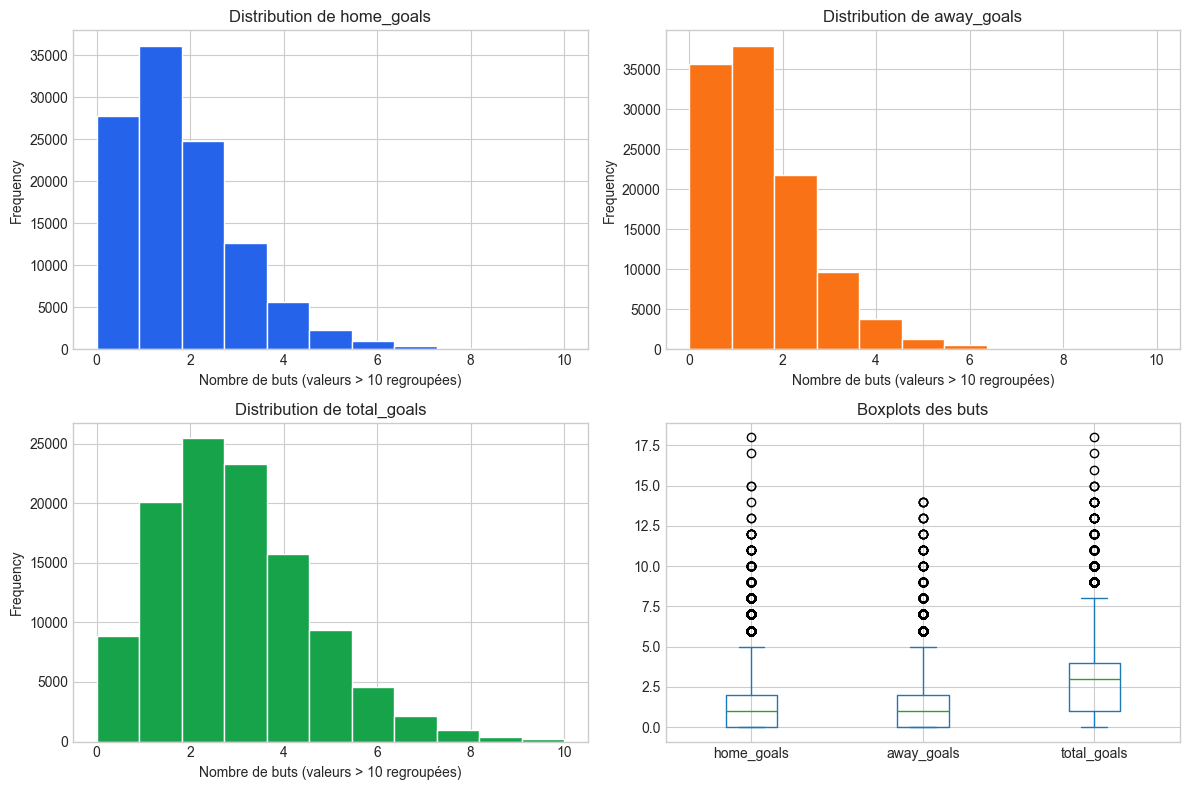

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
colors = ["#2563eb", "#f97316", "#16a34a"]
for ax, column, color in zip(axes.flat[:3], ["home_goals", "away_goals", "total_goals"], colors):
    eda[column].clip(upper=10).plot(kind="hist", bins=11, ax=ax, color=color, edgecolor="white")
    ax.set_title(f"Distribution de {column}")
    ax.set_xlabel("Nombre de buts (valeurs > 10 regroupées)")
eda[["home_goals", "away_goals", "total_goals"]].plot(kind="box", ax=axes.flat[3])
axes.flat[3].set_title("Boxplots des buts")
plt.tight_layout()
plt.show()

## 3.2 Variables catégorielles

Effectifs, proportions et catégories rares.

In [20]:
target_counts = eda["target"].value_counts().reindex(["home", "draw", "away"])
target_analysis = pd.DataFrame({
    "effectif": target_counts,
    "proportion_pct": 100 * target_counts / target_counts.sum(),
})
league_counts = eda["league_name"].value_counts()
rare_leagues = league_counts[league_counts < 10]
display(target_analysis)
print(f"Ligues représentées : {league_counts.size:,}")
print(f"Ligues rares avec moins de 10 matchs : {rare_leagues.size:,}")
display(rare_leagues.head(20).to_frame("effectif"))

,effectif,proportion_pct
target,,
home,48113,43.37
draw,27651,24.92
away,35174,31.71


Ligues représentées : 727
Ligues rares avec moins de 10 matchs : 105


,effectif
league_name,
K-League Classic,9
Oberliga: Bayern Süd,9
Coppa Italia Serie C,9
Faroe Islands Cup,9
3. Lig Play-offs,9
Landesliga: Vorarlberg,9
3. HNL - North,9
Mtn 8 Cup,9
Cearense 2,9


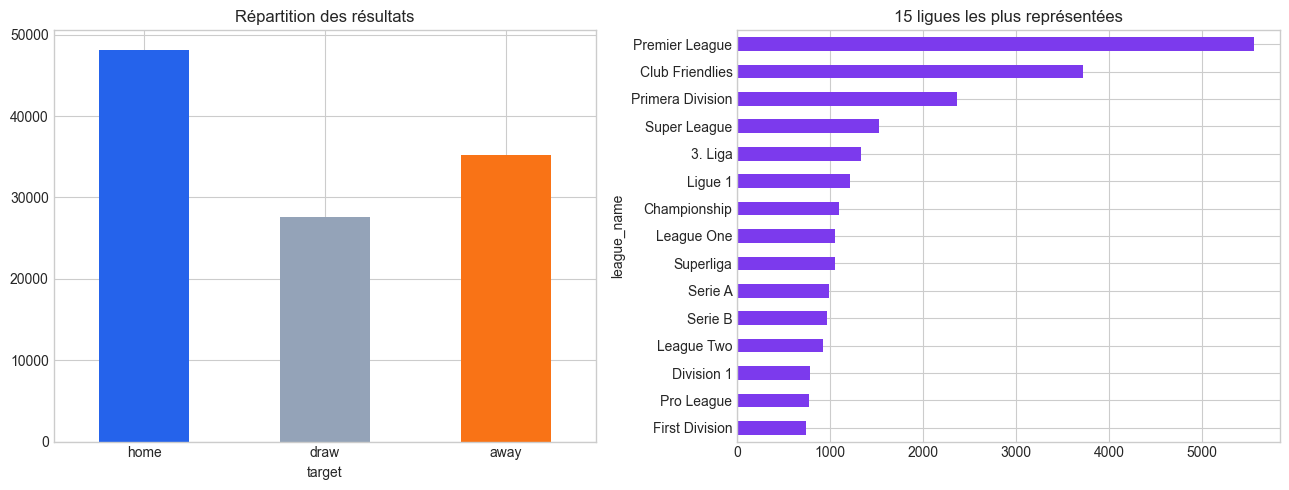

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
target_counts.plot(kind="bar", ax=axes[0], color=["#2563eb", "#94a3b8", "#f97316"])
axes[0].set_title("Répartition des résultats")
axes[0].tick_params(axis="x", rotation=0)
league_counts.head(15).sort_values().plot(kind="barh", ax=axes[1], color="#7c3aed")
axes[1].set_title("15 ligues les plus représentées")
plt.tight_layout()
plt.show()

## 3.3 Évolution dans le temps

Évolution du volume de matchs et des proportions de résultats. Une rupture brutale peut signaler un changement de couverture plutôt qu'un phénomène sportif.

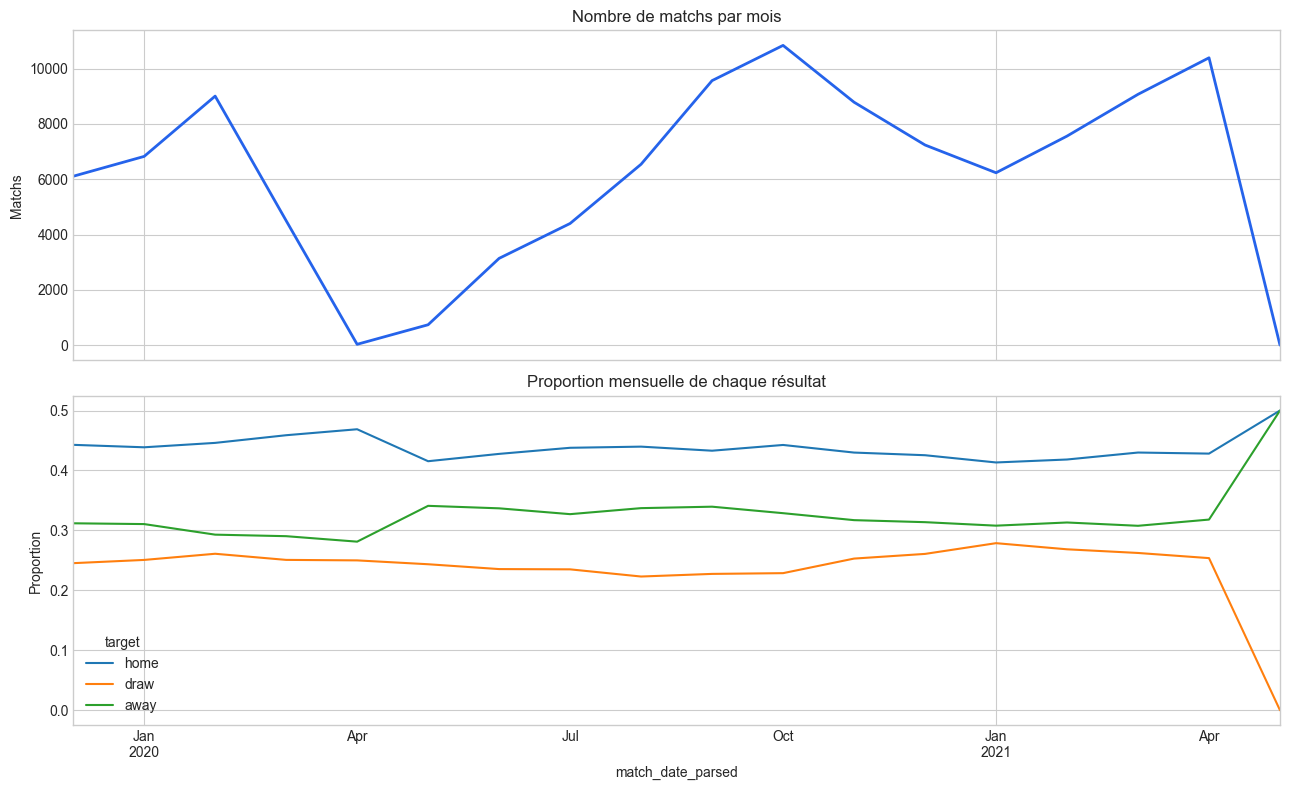

Période couverte : 2019-12-01 au 2021-05-01


In [22]:
time_data = eda.dropna(subset=["match_date_parsed"]).copy()
monthly_matches = time_data.set_index("match_date_parsed").resample("ME").size()
monthly_target_share = (
    time_data.groupby([pd.Grouper(key="match_date_parsed", freq="ME"), "target"])
    .size()
    .unstack(fill_value=0)
)
monthly_target_share = monthly_target_share.div(monthly_target_share.sum(axis=1), axis=0)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
monthly_matches.plot(ax=axes[0], color="#2563eb", linewidth=2)
axes[0].set_title("Nombre de matchs par mois")
axes[0].set_ylabel("Matchs")
monthly_target_share[[c for c in ["home", "draw", "away"] if c in monthly_target_share]].plot(ax=axes[1])
axes[1].set_title("Proportion mensuelle de chaque résultat")
axes[1].set_ylabel("Proportion")
plt.tight_layout()
plt.show()

print(f"Période couverte : {time_data['match_date_parsed'].min().date()} au {time_data['match_date_parsed'].max().date()}")

In [23]:
seasonality = time_data.assign(month=time_data["match_date_parsed"].dt.month).groupby("month").agg(
    matches=("id", "size"),
    average_total_goals=("total_goals", "mean"),
)
seasonality

,matches,average_total_goals
month,,
1,13055,2.65
2,16559,2.63
3,13568,2.61
4,10419,2.68
5,741,3.13
6,3138,2.99
7,4399,3.04
8,6540,3.03
9,9562,3.01


## 3.4 Comparaison de groupes avec `groupby()`

In [24]:
league_statistics = eda.groupby("league_name").agg(
    matches=("id", "size"),
    average_home_goals=("home_goals", "mean"),
    average_away_goals=("away_goals", "mean"),
    average_total_goals=("total_goals", "mean"),
)
result_by_league = pd.crosstab(eda["league_name"], eda["target"], normalize="index")
league_statistics = league_statistics.join(result_by_league).query("matches >= 100")
league_statistics.sort_values("matches", ascending=False).head(20)

,matches,average_home_goals,average_away_goals,average_total_goals,away,draw,home
league_name,,,,,,,
Premier League,5565,1.36,1.19,2.55,0.33,0.27,0.40
Club Friendlies,3724,1.86,1.43,3.29,0.31,0.23,0.46
Primera Division,2369,1.41,1.12,2.53,0.28,0.30,0.43
Super League,1530,1.40,1.09,2.49,0.29,0.29,0.43
3. Liga,1327,1.55,1.34,2.90,0.34,0.24,0.42
Ligue 1,1210,1.29,1.06,2.35,0.29,0.30,0.41
Championship,1097,1.32,1.17,2.49,0.34,0.26,0.40
League One,1050,1.37,1.18,2.55,0.32,0.26,0.42
Superliga,1048,1.40,1.20,2.60,0.32,0.26,0.42


## 3.5 Relations entre deux variables

Tableau croisé pour deux variables catégorielles, puis corrélations et scatterplot pour des variables numériques pertinentes.

target,away,draw,home
is_cup,,,
False,31.35,25.24,43.41
True,35.70,21.41,42.89


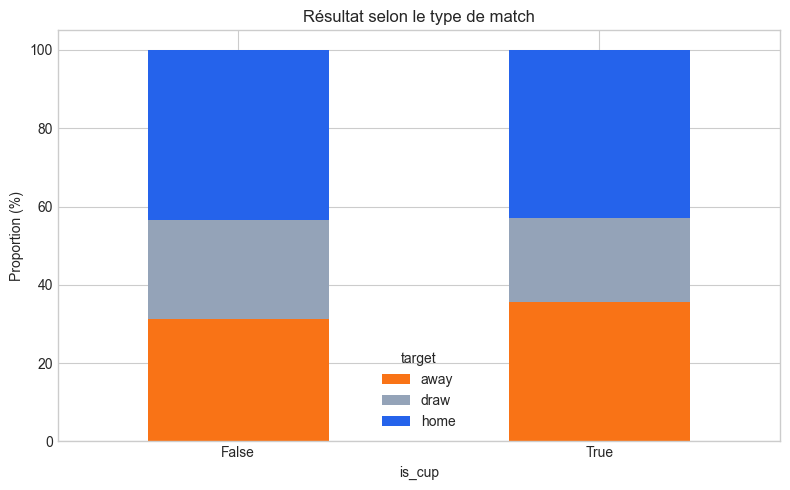

In [25]:
cup_target_crosstab = pd.crosstab(
    eda["is_cup"],
    eda["target"],
    normalize="index",
) * 100
display(cup_target_crosstab.round(2))
cup_target_crosstab.plot(kind="bar", stacked=True, figsize=(8, 5), color=["#f97316", "#94a3b8", "#2563eb"])
plt.title("Résultat selon le type de match")
plt.ylabel("Proportion (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,home_recent_goals_mean,away_recent_goals_mean,recent_rating_difference,home_goals,away_goals,total_goals
home_recent_goals_mean,1.00,0.18,0.39,0.21,-0.04,0.14
away_recent_goals_mean,0.18,1.00,-0.38,-0.05,0.19,0.09
recent_rating_difference,0.39,-0.38,1.00,0.25,-0.23,0.04
home_goals,0.21,-0.05,0.25,1.00,-0.08,0.72
away_goals,-0.04,0.19,-0.23,-0.08,1.00,0.63
total_goals,0.14,0.09,0.04,0.72,0.63,1.00


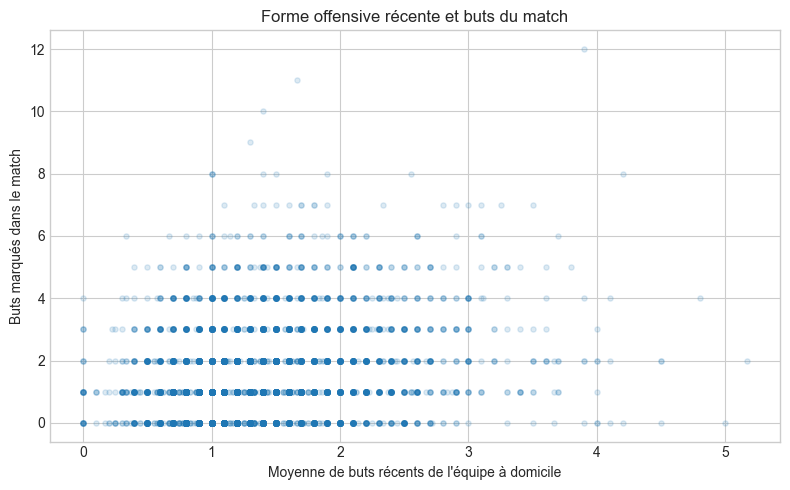

In [26]:
correlation_columns = [
    "home_recent_goals_mean", "away_recent_goals_mean",
    "recent_rating_difference", "home_goals", "away_goals", "total_goals",
]
correlations = eda[correlation_columns].corr()
display(correlations.round(3))

scatter_data = eda[["home_recent_goals_mean", "home_goals"]].dropna()
scatter_data = scatter_data.sample(min(5000, len(scatter_data)), random_state=42)
plt.figure(figsize=(8, 5))
plt.scatter(scatter_data["home_recent_goals_mean"], scatter_data["home_goals"], alpha=0.15, s=14)
plt.xlabel("Moyenne de buts récents de l'équipe à domicile")
plt.ylabel("Buts marqués dans le match")
plt.title("Forme offensive récente et buts du match")
plt.tight_layout()
plt.show()

## Réponse à la partie 3 — Que racontent ces variables ?

In [27]:
target_percentages = (100 * eda["target"].value_counts(normalize=True)).round(2)
rating_goal_corr = eda[["recent_rating_difference", "home_goals"]].corr().iloc[0, 1]
recent_form_corr = eda[["home_recent_goals_mean", "home_goals"]].corr().iloc[0, 1]
print("RÉPONSE : les variables montrent un avantage du domicile, une forte hétérogénéité entre ligues et des relations prédictives réelles mais modérées.")
print(f"- Résultats : domicile {target_percentages.get('home', 0):.2f} %, nul {target_percentages.get('draw', 0):.2f} %, extérieur {target_percentages.get('away', 0):.2f} %.")
print(f"- Buts moyens : {eda['home_goals'].mean():.2f} à domicile, {eda['away_goals'].mean():.2f} à l'extérieur, {eda['total_goals'].mean():.2f} au total.")
print(f"- Couverture : {league_counts.size:,} ligues, dont {rare_leagues.size:,} avec moins de 10 matchs ; les comparaisons doivent donc tenir compte de la ligue.")
print(f"- La forme offensive récente est corrélée à {recent_form_corr:.3f} avec les buts du match à domicile.")
print(f"- La différence de rating récent est corrélée à {rating_goal_corr:.3f} avec les buts à domicile.")
print("- La couverture varie dans le temps : l'évaluation du modèle devra donc être chronologique.")
print("- Ces relations sont utiles pour prédire, mais une corrélation ne prouve pas une causalité.")

RÉPONSE : les variables montrent un avantage du domicile, une forte hétérogénéité entre ligues et des relations prédictives réelles mais modérées.
- Résultats : domicile 43.37 %, nul 24.92 %, extérieur 31.71 %.
- Buts moyens : 1.52 à domicile, 1.24 à l'extérieur, 2.76 au total.
- Couverture : 727 ligues, dont 105 avec moins de 10 matchs ; les comparaisons doivent donc tenir compte de la ligue.
- La forme offensive récente est corrélée à 0.209 avec les buts du match à domicile.
- La différence de rating récent est corrélée à 0.252 avec les buts à domicile.
- La couverture varie dans le temps : l'évaluation du modèle devra donc être chronologique.
- Ces relations sont utiles pour prédire, mais une corrélation ne prouve pas une causalité.
